# Figure 5: methylation-dependent accessibility of TF motifs, transposable elements and TSSs

Cheng, Stok Ranen et al., bioRxiv, doi:10.64898/2026.05.14.725081.

- **5a**: motif clusters on CREs: WT accessibility, Dnmt-TKO gain, Tet-TKO loss, methylation (section: Motif screen on CREs)
- **5b**: largest LTR, LINE and SINE subfamilies, and affected IAP subfamilies (section: Transposable element accessibility)
- **5c**: TSS clusters: WT accessibility, accessibility and expression change (section: TSS clusters)
- **5d**: host vs Dnmt-TKO expression of example genes (section: Expression barplots); tracks in `Fig4.ipynb` (section: Genome browser tracks)
- **ED8a**: Jaccard co-occurrence of motif loci (section: Motif co-occurrence matrix)
- **ED8b**: motif screen on TSS peaks (section: Motif screen on TSS peaks)
- **ED8c**: Dnmt-TKO vs Dnmt-DKO expression ratios, TSS genes highlighted (section: Methylation-sensitive TSS genes)
- **ED8d**: accessibility change of CREs near 5c TSSs (section: Neighbouring CREs)

Notes:
- Three parts (5a + ED8a, b; 5b; 5c, d + ED8c, d). Each loads its own libraries and scripts and re-reads `data/output/mod.RDS`.
- Figures go through `out_path()`, so under `git_test/`.

## Initialization

In [1]:
source("paths.R")
save_figure = F  # TRUE also writes every figure to git_test/ (see show_fig() in paths.R)

## Fig. 5a, ED8a, ED8b: TF motifs

Screens TF motifs for CREs whose accessibility changes in Dnmt-TKO or Tet-TKO, per CpG bin and lineage, and clusters the significant motifs. Heatmaps go to `figs/Fig5/`.

### Setup

In [2]:
library(misha)
library(tibble)
library(dplyr)
library(ggplot2)
library(iceqream)
library(prego)
library(misha.ext)
library(purrr)
library(tidyr)
library(pheatmap)

gsetroot(mm10_trackdb)
options(gmax.data.size = 1e+9)

In [3]:
source(file.path(repo_dir, "scripts/lineage_peaks_func.r"))
source(file.path(repo_dir, "scripts/motif_screen_func.r"))

- `gen_peaks_lin` (`scripts/lineage_peaks_func.r`): peak-by-genotype counts (WT, Dnmt-TKO, Dnmt-DKO, Tet-TKO) in three lineages, each downsampled to the smallest of its WT, Dnmt-TKO and Tet-TKO totals:
  - `rnp`: rostral neural plate (Ecto)
  - `acp`: allantois/chorion and progenitors (ExMeso)
  - `meso`: paraxial and cardiac mesoderm (Meso)
- `add_peak_energ` (`scripts/motif_screen_func.r`): PREGO binding energy of HOMER, JASPAR, Jolma and two SCENIC motifs over the central 300 bp of each peak.
- Cached in `data/output/lin_peaks.RDS` and `data/output/npeaks_energ_raw.RDS`; read when present.

In [4]:
mod = readRDS(in_path("./data/output/mod.RDS"))

In [5]:
mod <- gen_peaks_lin(mod)
mod <- add_peak_energ(mod)

### Motif screen on CREs (Fig. 5a)
- **5a**: motifs linked to methylation-dependent accessibility, per CpG bin (1: 0-1% to 6: >5%), in Ecto, Meso and ExMeso

Steps (`scripts/motif_screen_func.r`):
- `add_pwms_stats_v_wt`: distal peaks (> 1 kb from a TSS), log2 relative accessibility (pseudocount 1e-6); tests Dnmt-TKO - WT (gain) and WT - Tet-TKO (loss).
- `stratify_stat_by_pwms`: per CpG bin, top-2% energy peaks vs peaks below the 95th percentile, one-sided KS tests both ways (both groups > 100 peaks). Also mean accessibility of top-2% peaks per bin (empty if < 10 peaks).
- Statistics cached in `data/output/pwms_stat_v_wt.RDS`.
- `screen_pwms`: max KS D over CpG bins 1-5, FDR-corrected; keeps motifs with D > 0.25 at q < 1e-4.
- `plot_clust_pwms`: TGL k-means (k = 16, seed 19) on WT accessibility (column-centred), 2 x (Dnmt-TKO - WT) and 6 x (WT - Tet-TKO).
- `calc_meth_stats`: mean WT and Tet-TKO EM-seq methylation (E8.5 chimera tracks, coverage >= 10) of top-2% peaks per bin.
- The first `add_pwms_stats_v_wt` call and re-sourcing of `scripts/motif_screen_func.r` are redundant.

In [6]:
mod <- add_pwms_stats_v_wt(mod)

In [7]:
source(file.path(repo_dir, "scripts/motif_screen_func.r"))

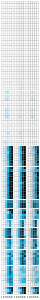

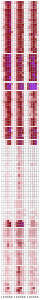

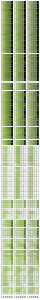

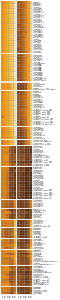

In [8]:
# CRE screen - main

mod <- add_pwms_stats_v_wt(mod)
screen_res = screen_pwms(ps = mod$pwms_stat_v_wt)
plot_clust_pwms(ps = mod$pwms_stat_v_wt, screen_res = screen_res)

Writes the four **5a** blocks (lineages ordered Ecto, ExMeso, Meso) to `figs/Fig5/final_heatmaps/`:
- `pwm_km_trends.png`: WT accessibility (green)
- `pwm_km_dnmt.png`: Dnmt-TKO - WT (blue)
- `pwm_km_tet.png`: WT - Tet-TKO (red)
- `pwm_km_meth.png`: WT and Tet-TKO methylation (orange), with motif names

Also writes:
- Colour scales: `figs/Fig5/scales_to_scale/5A_scales/top_{wt,dnmt,tet,meth}_scale.pdf`
- k-means: `data/output/pwm_trends_km.RDS`; matrices: `data/output/pwm_trends_{abs,diff,dnmt,tet}.RDS`
- Next cell: significant motifs to `data/output/foc_pwms.RDS` (read by `Fig4.ipynb`)

Caveats:
- The 5a motif logos are not drawn here.
- The cell after `foc_pwms.RDS` computes rnp and ExE mesoderm matrices that nothing uses.

In [9]:
saveRDS(screen_res$foc_pwms, out_path("./data/output/foc_pwms.RDS"))

### Motif screen on TSS peaks (ED8b)
- **ED8b**: the 5a screen on TSS loci, CpG bins 0-2%, 2-4%, 4-6%, 6-8%, >8%

Same screen on peaks within 1 kb of a TSS (`add_pwms_stats_TSS`, `screen_pwms_TSS`, `plot_clust_pwms_TSS`; statistics cached in `data/output/pwms_stats_TSS.RDS`).
- The KS screen tests Dnmt-TKO - Tet-TKO, not each mutant vs WT; the heatmap blocks are still vs WT.
- `plot_clust_pwms_TSS` writes `pwm_trends_km.RDS`, the same file as the CRE clustering. Here the write goes under `git_test/` and the co-occurrence matrix reads from `data/`, so it uses the CRE clustering. If both pointed to one directory, the matrix would be ordered by the TSS clustering.

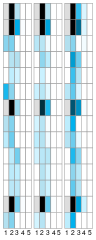

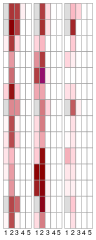

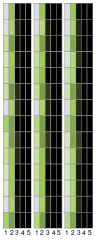

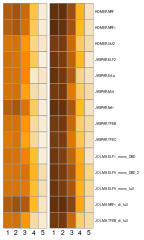

In [10]:
# TSS screen - supp

mod <- add_pwms_stats_TSS(mod)
screen_res_TSS = screen_pwms_TSS(ps = mod$pwms_stats_TSS)
plot_clust_pwms_TSS(ps = mod$pwms_stats_TSS, screen_res = screen_res_TSS)

- Heatmaps: `figs/Fig5/final_heatmaps/pwm_km_{trends,dnmt,tet,meth}_TSS.pdf`
- Next cell: logos of significant TSS motifs to `figs/Fig5/pdf_logos_TSS/<motif>.pdf`

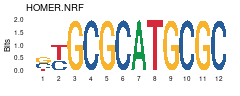

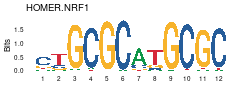

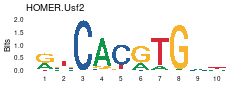

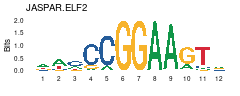

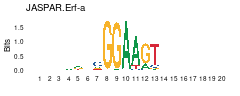

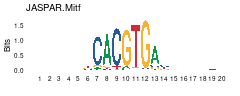

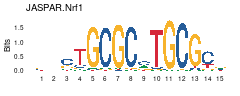

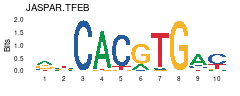

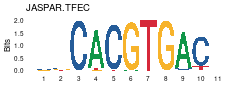

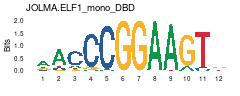

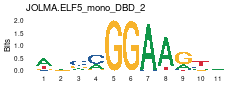

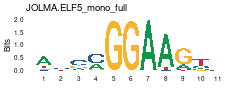

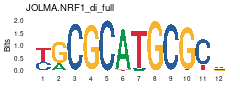

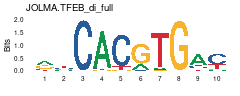

In [11]:
load("data/ref/motif_db.rda")
nms = screen_res_TSS$foc_pwms
for (pnm in nms) {
    message("plt logo ", pnm)
    a = plot_pssm_logo_dataset(pnm, dataset = motif_db)
    show_fig(sprintf("figs/Fig5/pdf_logos_TSS/%s.pdf", gsub("/", ".", gsub("::", "", pnm))), height = 2, width = 5,
             draw = print(a))
}

### Motif co-occurrence matrix (ED8a)
- **ED8a**: Jaccard similarity of motif loci, motifs in 5a row order

- Motifs ordered by k-means cluster (`data/output/pwm_trends_km.RDS`).
- Hit set: distal peaks with energy above the motif's 98th percentile.
- Jaccard similarity for every motif pair, with gaps between clusters.

In [12]:
pwm_trends_km = readRDS(in_path("./data/output/pwm_trends_km.RDS"))

In [13]:
mot_order = names(sort(pwm_trends_km$cluster))
gaps = which(!duplicated(sort(pwm_trends_km$cluster)))
gaps = gaps[2:length(gaps)]
gaps = gaps - 1

In [14]:
energ = mod$npeaks_energ[,-c(1:3,6:8)]
npeaks = mod$npeaks
npeaks$cgbin = as.numeric(cut(npeaks$CG, c(seq(0,0.06,0.01),1)))
peak_filter = abs(mod$npeaks$d_tss)>1000

e_foc = energ[peak_filter, mot_order]
tope_mask = apply(e_foc, 2, function(x) {x > quantile(x, 0.98, na.rm=T)})

In [15]:
npeaks_foc = npeaks[peak_filter,]

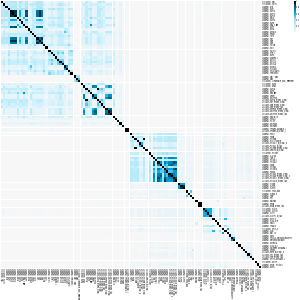

In [16]:
mat = tope_mask

# Convert to numeric matrix for multiplication
mat_numeric <- mat * 1  # Convert TRUE/FALSE to 1/0

# Calculate co-occurrence matrix using vector multiplication
co_occurrence_matrix <- t(mat_numeric) %*% mat_numeric

# Jaccard similarity
# Divide by the union of each pair (number of rows where at least one is TRUE)
union_matrix <- outer(
  colSums(mat_numeric), 
  colSums(mat_numeric), 
  FUN = function(x, y) x + y - co_occurrence_matrix
)
jaccard_similarity_matrix <- co_occurrence_matrix / union_matrix

options(repr.plot.width = 20, repr.plot.height = 20)
show_fig("./figs/Fig5/Supp_similarity_matrix.pdf", draw = pheatmap(jaccard_similarity_matrix[mot_order,mot_order], cluster_rows = F, cluster_cols = F,
         gaps_row = gaps, gaps_col = gaps, h=20, w=20,
         color = colorRampPalette(c("grey97", "lightblue1", "lightblue2", "deepskyblue2", "deepskyblue4", "black"))(100)))

Writes `figs/Fig5/Supp_similarity_matrix.pdf` (**ED8a**); nothing is drawn in the notebook.

## Fig. 5b: transposable elements

Total ATAC coverage of repeat subfamilies in WT, Dnmt-TKO, Dnmt-DKO and Tet-TKO, pooled over all lineages. Figures go to `figs/Fig5/TE/`.

- Coverage comes from tracks of the unfiltered `atac_possorted_bam.bam`, since CellRanger output drops multi-mapped reads (most repeats).

### Setup

In [17]:
library(Rsamtools)
library(GenomicRanges)
library(dplyr)
library(tidyr)
library(ggplot2)

library(misha.ext)
library(misha)
gsetroot(mm10_trackdb)

library(data.table)

#### Raw marginal tracks (run once)
- The bash cell filters a mutant's `atac_possorted_bam.bam` to a list of cell barcodes (shown for Dnmt-DKO).
- The next cell imports the Dnmt-TKO and Dnmt-DKO BAMs as misha tracks `mut_multi.DNMT_{TKO,DKO}_KO.raw`, keeping duplicates.
- `write_filtered_raw_marginals = F` skips the import and uses the existing tracks.
- WT (`mut_multi.WT_lg.raw`, `mut_multi.WT_sm.raw`) and Tet-TKO (`mut_multi.TET_TKO_KO.raw`) tracks must already exist; nothing here makes them.

In [18]:
write_filtered_raw_marginals = F
if (write_filtered_raw_marginals){
    gdb.reload()
    
    gtrack.import_mappedseq_bam(bam_files = paste0(tg_atac_dir, "/mm_gastru/DNMT_TKO_KO/outs/atac_possorted_bam_karyo_f.bam"),
                                track = "mut_multi.DNMT_TKO_KO.raw",
                                description = "Marginal track straight from filtered BAM.",
                                remove.dups = F)
    
    gtrack.import_mappedseq_bam(bam_files = paste0(tg_atac_dir, "/mm_gastru/DNMT_DKO_KO/outs/atac_possorted_bam_karyo_f.bam"),
                            track = "mut_multi.DNMT_DKO_KO.raw",
                            description = "Marginal track straight from filtered BAM.",
                            remove.dups = F)
}

In [19]:
source(file.path(repo_dir, "scripts/ATAC_preprocessing.r"))
source(file.path(repo_dir, "scripts/Fig5_func.r"))
mod <- readRDS(in_path("./data/output/mod.RDS"))

In [20]:
gdb.reload()

#### Normalization
- `r_to_dsamp`: downsampling ratios bringing all four genotypes to the smallest total (WT = large + small libraries).
- Aneuploid chromosomes: mutant/WT coverage ratio > 1.06 (`mod$cov_chr`); printed for Tet-TKO, Dnmt-TKO, Dnmt-DKO.
- `generate_marg_df` sums reads per element; `process_atac` downsamples flagged chromosomes by their ratio, then everything by `r_to_dsamp`.

In [21]:
tot_tko = gsummary("mut_multi.DNMT_TKO_KO.raw")[["Sum"]]
tot_dko = gsummary("mut_multi.DNMT_DKO_KO.raw")[["Sum"]]

tot_tet = gsummary("mut_multi.TET_TKO_KO.raw")[["Sum"]]
tot_wtl = gsummary("mut_multi.WT_lg.raw")[["Sum"]]
tot_wts = gsummary("mut_multi.WT_sm.raw")[["Sum"]]
tot_wt = tot_wtl + tot_wts

r_chr_cov_tko = mod$cov_chr[["DNMT_TKO_KO"]]/(mod$cov_chr[["WT_lg"]]+mod$cov_chr[["WT_sm"]])
r_chr_cov_tko = r_chr_cov_tko/apply(r_chr_cov_tko, 1, median, na.rm=T)

r_chr_cov_dko = mod$cov_chr[["DNMT_DKO_KO"]]/(mod$cov_chr[["WT_lg"]]+mod$cov_chr[["WT_sm"]])
r_chr_cov_dko = r_chr_cov_dko/apply(r_chr_cov_dko, 1, median, na.rm=T)

r_chr_cov_tet = mod$cov_chr[["TET_TKO_KO"]]/(mod$cov_chr[["WT_lg"]]+mod$cov_chr[["WT_sm"]])
r_chr_cov_tet = r_chr_cov_tet/apply(r_chr_cov_tet, 1, median, na.rm=T)

which(r_chr_cov_tet["marginal",] > 1.06)
which(r_chr_cov_tko["marginal",] > 1.06)
which(r_chr_cov_dko["marginal",] > 1.06)

tr_karyo = list()
tr_karyo[["wt"]] = NULL
tr_karyo[["tko"]] = r_chr_cov_tko["marginal",]
tr_karyo[["dko"]] = r_chr_cov_dko["marginal",]
tr_karyo[["tet"]] = r_chr_cov_tet["marginal",]

min_tot = pmin(tot_tko, tot_dko, tot_tet, tot_wt)
r_to_dsamp = data.frame(wt = min_tot/tot_wt, 
                        tko = min_tot/tot_tko, 
                        dko = min_tot/tot_dko, 
                        tet = min_tot/tot_tet)

### Transposable element accessibility (Fig. 5b)
- **5b**: log normalized total accessibility of TE subfamilies per genotype, summed over all cells

- Elements: UCSC RepeatMasker LTR, LINE and SINE (`intervs.global.rmsk_ltr`, `_line`, `_sine`).
- Boxes: log2(0.25 + normalized count) over the elements of a subfamily.
- `plot_largest_families`: the five subfamilies with the most elements per class.
- IAP plot: IAP subfamilies with median Dnmt-TKO - WT normalized count > 20.

In [22]:
LTR = gintervals.load('intervs.global.rmsk_ltr')
LINE = gintervals.load('intervs.global.rmsk_line')
SINE = gintervals.load('intervs.global.rmsk_sine')

In [23]:
LTR_marg = generate_marg_df(LTR)
LTR_proc = process_atac(LTR_marg, tr_karyo, r_to_dsamp)

LINE_marg = generate_marg_df(LINE)
LINE_proc = process_atac(LINE_marg, tr_karyo, r_to_dsamp)

SINE_marg = generate_marg_df(SINE)
SINE_proc = process_atac(SINE_marg, tr_karyo, r_to_dsamp)

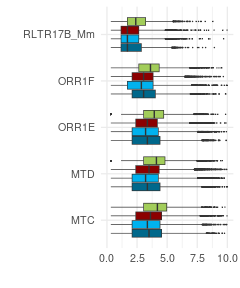

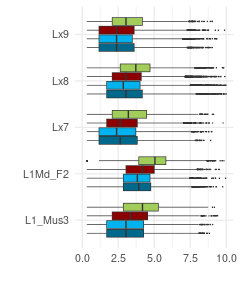

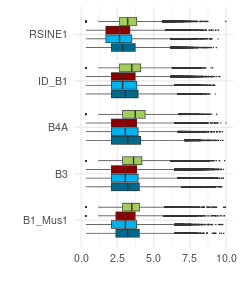

In [24]:
options(repr.plot.width = 5, repr.plot.height = 5)

p <- plot_largest_families(LTR_proc)
show_fig("./figs/Fig5/TE/LTR_largest_families.pdf", p, width = 5, height = 6)

p <- plot_largest_families(LINE_proc)
show_fig("./figs/Fig5/TE/LINE_largest_families.pdf", p, width = 5, height = 6)

p <- plot_largest_families(SINE_proc)
show_fig("./figs/Fig5/TE/SINE_largest_families.pdf", p, width = 5, height = 6)

Writes **5b** LTR, LINE and SINE plots: `figs/Fig5/TE/LTR_largest_families.pdf`, `LINE_largest_families.pdf`, `SINE_largest_families.pdf`.

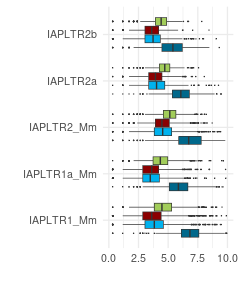

In [25]:
options(repr.plot.width = 5, repr.plot.height = 6)

IAP_f = LTR_proc %>% 
    filter(grepl("IAP", name)) %>%
    group_by(name) %>%
    summarise(diff = median(tko - wt)) %>%
    filter(diff > 20) %>% pull(name)

p_iap = LTR_proc %>% 
    filter(name %in% IAP_f) %>%
    select(name, wt, tko, dko, tet) %>% pivot_longer(-name, names_to = "origin",) %>%
    mutate(origin = factor(origin, c("tko", "dko", "tet", "wt")), value = log2(0.25+value)) %>%
    ggplot(aes(value, name, fill = origin)) + geom_boxplot(outlier.size = 0.4) + theme_minimal(base_size = 20) + 
        scale_fill_manual(values = c("wt" = "darkolivegreen3", "tko" = "deepskyblue4", "dko" = "deepskyblue2", "tet" = "darkred")) +
        xlab("") + ylab("") +
        theme(legend.position = "none") + 
        xlim(0,10)

show_fig("./figs/Fig5/TE/IAP_affected.pdf", p_iap, width = 5, height = 6)

Writes the **5b** IAP plot: `figs/Fig5/TE/IAP_affected.pdf`.
- IAP subfamilies are selected on the Dnmt-TKO - WT difference itself.

## Fig. 5c, 5d, ED8c, ED8d: TSSs

Groups TSSs by Dnmt-TKO accessibility and expression change, clusters each group, and plots related panels. Figures go to `figs/`.

- Stored outputs come from out-of-order runs; cells from section "Neighbouring CREs" on have no stored outputs.

### Setup

In [26]:
library(dplyr)

In [27]:
library(misha)

gsetroot(mm10_trackdb)
source(file.path(repo_dir, "scripts/Fig5_func.r"))

In [28]:
mod = readRDS(in_path("./data/output/mod.RDS"))

- `load_expression` (`scripts/Fig5_func.r`): reads `data/output/rna_stat.RDS`, incl. `mdlt_full` (log2 KO/host relative expression, pseudocount 1e-5, per Dnmt genotype and lineage).
- `gen_peaks_lin` (`scripts/lineage_peaks_func.r`): peak counts (WT, Dnmt-TKO, Dnmt-DKO, Tet-TKO) for Ecto (rostral neural plate), ExMeso (allantois/chorion and progenitors) and Meso (paraxial and cardiac mesoderm).

In [29]:
mod <- load_expression(mod)

In [30]:
source(file.path(repo_dir, "scripts/lineage_peaks_func.r"))
mod <- gen_peaks_lin(mod)

### TSS clusters (Fig. 5c)
- **5c**: TSS clusters by Dnmt-TKO vs WT accessibility and expression change (pooled over three lineages), with mean WT accessibility; full data in Supplementary Table 3

`plt_exp_atac_tss` (`scripts/Fig5_func.r`):
- Peaks within 1 kb of an annotated (UCSC) TSS of a gene in the RNA data; accessibility change = Dnmt-TKO - WT log2 relative accessibility per lineage; left column = mean WT accessibility.
- One peak per gene: the largest mean accessibility change. Imprinted genes removed.
- Accessibility change set to 0 unless chi-square Dnmt-TKO vs WT gives FDR q <= 0.01 (peaks with < 10 reads left out; cached in `data/output/atac_chisq.RDS`).
- Expression change per lineage = sum of Dnmt-TKO and Dnmt-DKO log2(KO/host); set to 0 unless the Dnmt-TKO chi-square screen (`data/output/chisq_screen.RDS`) gives q <= 0.01.
- Groups: accessibility change > 0.8 and/or expression change > 1: "11" (both), "10" (accessibility only), "01" (expression only).
- Each group: TGL k-means (k = 10, seed 19); rows by cluster, then WT accessibility.

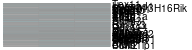

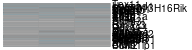

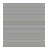

In [31]:
source(file.path(repo_dir, "scripts/Fig5_func.r"))
mod <- plt_exp_atac_tss(mod)

Writes, for group "11" only:
- `figs/Fig5/final_heatmaps/tss_atac_11.no_gaps.pdf` (accessibility change, blue)
- `tss_rna_11.no_gaps.pdf` (expression change, cadet blue)
- `tss_abs_a_11.no_gaps.pdf` (WT accessibility, green)
- `data/summary/tss_km_11.txt` (clusters), `data/output/5C_kord_11.RDS` (row order)
- Gene labels: only genes in `data/ref/5C_highlight.csv`

In **5c**, upper/middle/lower heatmaps are groups "11", "10", "01" (stored tables: 105, 562, 391 TSSs, matching the paper). `Supp_tables.ipynb` combines them into `data/supp_tables/TableS1.csv` (paper Supplementary Table 3).

### Expression barplots (Fig. 5d)
- **5d**: ectoderm accessibility tracks and host vs Dnmt-TKO expression at TSSs from 5c

- Next three cells: load `RNA_mod` (`init_RNA_mod`, `scripts/rna_projection_func.r`) and take median metacell log2 expression per cell type for Dnmt-TKO chimera KO and host.

In [32]:
source(file.path(repo_dir, "scripts/rna_projection_func.r"))

In [33]:
RNA_mod <- init_RNA_mod(reload_data = FALSE)

In [34]:
DNMT_TKO_KO = t(tgs_matrix_tapply(RNA_mod[["DNMT_TKO_KO"]]$legc, RNA_mod[["DNMT_TKO_KO"]]$mc_to_type, median))
DNMT_TKO_host = t(tgs_matrix_tapply(RNA_mod[["DNMT_TKO_host"]]$legc, RNA_mod[["DNMT_TKO_host"]]$mc_to_type, median))

Barplots: median rostral neural plate expression of Ifitm3, Asz1 and Snf8, host (grey) vs Dnmt-TKO (blue), log2 axis floored at log2(1e-5).

In [35]:
highlight_gns = c("Ifitm3", "Asz1", "Snf8")
highlight_ct = "Rostral neural plate"
df_long = 
full_join(enframe(DNMT_TKO_KO[highlight_gns, highlight_ct], name = "gene", value = "KO"),
          enframe(DNMT_TKO_host[highlight_gns, highlight_ct], name = "gene", value = "host")) %>%
    pivot_longer(-gene, names_to = "group", values_to = "value")

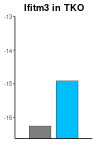

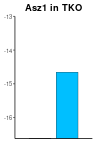

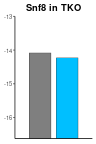

In [36]:
lower_y <- log2(1e-5)-0.01
dodge_w <- 0.35 
bar_w   <- 0.28
min_h   <- 0.08

highlight_gn <- "Ifitm3"

options(repr.plot.width = 2, repr.plot.height = 3)
p_ifitm3 = plot_paired_bars("Ifitm3", -13)
p_asz1 = plot_paired_bars("Asz1", -13)
p_snf8 = plot_paired_bars("Snf8", -13)
show_fig("./figs/Fig5/ifitm3_barplot.pdf", p_ifitm3, width = 2, height = 3)
show_fig("./figs/Fig5/asz1_barplot.pdf", p_asz1, width = 2, height = 3)
show_fig("./figs/Fig5/snf8_barplot.pdf", p_snf8, width = 2, height = 3)

Writes the **5d** barplots: `figs/Fig5/ifitm3_barplot.pdf`, `asz1_barplot.pdf`, `snf8_barplot.pdf`.

### Methylation-sensitive TSS genes (ED8c)
- **ED8c**: log2(Dnmt-TKO/host) vs log2(Dnmt-DKO/host) for all genes in Ecto, EmbMeso and ExMeso; group "11" genes highlighted

- Highlighted genes: `data/summary/tss_km_11.txt` (section: TSS clusters). "11" is the group, not k-means cluster 11.
- `prep_single_cell()` (`scripts/single_cell_func.r`) loads KO and host pseudo-bulk counts (`data/output/mko.RDS`, `mhost.RDS`; rebuilt from `data/MC_models/RNA_all.h5ad` if missing). See `prep/ko_vs_host.ipynb`.
- Ratios: `sc$mdlt_full` (as in Fig. 2e); DKO on x, TKO on y; genes outside -3..3 dropped by axis limits.

In [37]:
source(file.path(repo_dir, "scripts/single_cell_func.r"))
sc <- prep_single_cell()

In [38]:
tss11 = read.table(in_path("./data/summary/tss_km_11.txt"))

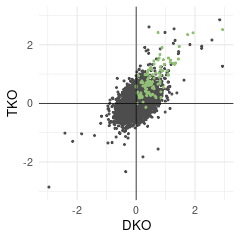

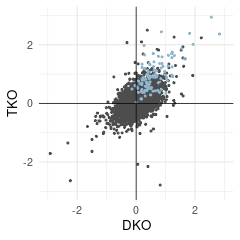

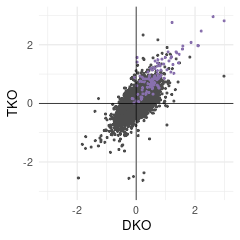

In [39]:
options(repr.plot.width = 5, repr.plot.height = 5)
    
plot_tss11(c("DNMT_TKO.Ecto", "DNMT_DKO.Ecto"), "#90BF75")
plot_tss11(c("DNMT_TKO.EmbMeso", "DNMT_DKO.EmbMeso"), "#8DB5CE")
plot_tss11(c("DNMT_TKO.ExMeso", "DNMT_DKO.ExMeso"), "#8870ad")

Writes **ED8c**: `figs/Supp/DNMT_TKO.Ecto_DNMT_DKO.Ecto.pdf`, `DNMT_TKO.EmbMeso_DNMT_DKO.EmbMeso.pdf`, `DNMT_TKO.ExMeso_DNMT_DKO.ExMeso.pdf`.

### Neighbouring CREs (ED8d)
- **ED8d**: Dnmt-TKO vs WT accessibility change of ICG/LCG laCREs near 5c TSSs, by distance, vs all CREs of that class

Setup:
- Reads the three TSS group tables from `data/summary/` (only "11" is rewritten here).
- Rostral neural plate accessibility change (Dnmt-TKO - WT) per peak; keeps peaks > 5 kb from a TSS, annotated with hotspot mode (`mod$ehs`).
- The cell trimming `peak_rnp_lf` selects columns by position.

In [40]:
tss11 = read.table(in_path("./data/summary/tss_km_11.txt"))
tss10 = read.table(in_path("./data/summary/tss_km_10.txt"))
tss01 = read.table(in_path("./data/summary/tss_km_01.txt"))

In [41]:
lp = mod$lin_peaks
u_rnp = lp$rnp_ds
e_rnp  = t(t(u_rnp)/colSums(u_rnp))
le_rnp = log2(1e-6+e_rnp)
rnp_lf = le_rnp[,2]-le_rnp[,1]

In [42]:
peak_rnp_lf = cbind(mod$npeaks, rnp_lf) %>% filter(abs(d_tss) > 5e+3)
peak_rnp_lf = gintervals.neighbors(peak_rnp_lf, mod$ehs[,c("chrom", "start", "end", "mode")], maxdist = 0) 

In [43]:
peak_rnp_lf = peak_rnp_lf %>% select(1:3, 9, 13) # %>% filter(mode == "icg_wenh") # pull(mode) %>% table() %>% sort()

In [44]:
tss01$class = "01"
tss11$class = "11"
tss10$class = "10"
tss_all = do.call(rbind, list(tss01, tss11, tss10))

Panel cell, for `icg_wenh` (ICG laCREs) and `lcg_wenh` (LCG laCREs):
- CREs within 100 kb of group "01" and "10" TSSs, binned by distance ("11" is filtered out).
- Per bin: cumulative distribution of accessibility change vs all CREs of the mode (black).
- The `icg_wenh` plot drops the 0-5 kb bin.

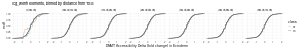

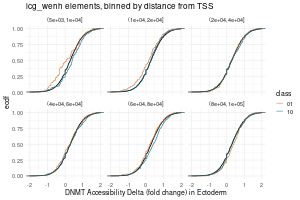

In [45]:
options(repr.plot.width = 9, repr.plot.height = 6)

icg_wenh_lf = peak_rnp_lf %>% filter(mode == "icg_wenh")
background_ecdf <- icg_wenh_lf %>%
  summarise(ecdf = ecdf(rnp_lf)(rnp_lf), rnp_lf) %>%
  distinct(rnp_lf, ecdf)

plot_df = gintervals.neighbors(tss_all, icg_wenh_lf, maxneighbors = 1e+3, maxdist = 1e+5, mindist = 0) %>%
    mutate(d_bin = cut(dist, breaks = c(0,5e+3,1e+4,2e+4,4e+4,6e+4,8e+4,1e+5), include.lowest = T)) %>%
    select(class, d_bin, rnp_lf) %>% filter(class != "11") %>% filter(d_bin != '[0,5e+03]')
p_icg = ggplot() + 
    geom_step(data = background_ecdf, aes(rnp_lf, ecdf), size = 0.8) + stat_ecdf(data = plot_df, aes(rnp_lf, color = class)) + 
    facet_wrap(~d_bin, nrow = 2) + theme_minimal(base_size = 15) + scale_color_manual(values = c("01" = "chocolate", "10" = "deepskyblue4", "background" = "black")) +
    ggtitle("icg_wenh elements, binned by distance from TSS") + xlim(-2,2) + xlab("DNMT Accessibility Delta (fold change) in Ectoderm")
print(p_icg)

lcg_wenh_lf = peak_rnp_lf %>% filter(mode == "lcg_wenh")
background_ecdf <- lcg_wenh_lf %>%
  summarise(ecdf = ecdf(rnp_lf)(rnp_lf), rnp_lf) %>%
  distinct(rnp_lf, ecdf)

plot_df = gintervals.neighbors(tss_all, lcg_wenh_lf, maxneighbors = 1e+3, maxdist = 1e+5, mindist = 0) %>%
    mutate(d_bin = cut(dist, breaks = c(0,5e+3,1e+4,2e+4,4e+4,6e+4,8e+4,1e+5), include.lowest = T)) %>%
    select(class, d_bin, rnp_lf) %>% filter(class != "11")
p_lcg = ggplot() + 
    geom_step(data = background_ecdf, aes(rnp_lf, ecdf), size = 0.8) + stat_ecdf(data = plot_df, aes(rnp_lf, color = class)) + 
    facet_wrap(~d_bin, nrow = 1) + theme_minimal(base_size = 15) + scale_color_manual(values = c("01" = "chocolate", "10" = "deepskyblue4", "background" = "black")) +
    ggtitle("lcg_wenh elements, binned by distance from TSS") + xlim(-2,2) + xlab("DNMT Accessibility Delta (fold change) in Ectoderm")

show_fig("./figs/Supp/lcg_wenh_S8C.pdf", p_lcg, width = 18, height = 3)

- Writes only the LCG part of **ED8d**: `figs/Supp/lcg_wenh_S8C.pdf` (old "S8C" name).
- The ICG plot is drawn but not saved (its `ggsave` is commented out).

### Fig. 5c colour scales
Writes the 5c colour bars to `figs/Fig5/scales_to_scale/`:
- `rna_scale.pdf` (0-3), `atac_scale.pdf` (0-3), `abs_atac_scale.pdf` (-20 to -13)
- The first cell's palettes are redefined by the second.

In [46]:
bshades = colorRampPalette(c("white", "lightblue1", "lightblue2", "deepskyblue2", "deepskyblue4", "black"))(1000)
bwshades = colorRampPalette(c("white", "black"))(1000)
gshades = colorRampPalette(c("white", "grey95", "darkolivegreen3", "darkolivegreen4", "darkolivegreen", "black"))(1000)

In [47]:
marg = c(2,1,2,8)

bshades = colorRampPalette(c("white", "lightblue1", "lightblue2", "deepskyblue2", "deepskyblue4", "black"))(1000)
show_fig("./figs/Fig5/scales_to_scale/rna_scale.pdf", show = FALSE, width = 5, height = 20, draw = {
    par(mar = marg)
    image(1, 1:100, t(as.matrix(1:100)), col = bshades, axes = FALSE, xlab = "", ylab = "")
    axis(4, at = seq(1, 100, length.out = 7), labels = round(seq(0, 3, length.out = 7), 2), las = 1, cex.axis = 5)
})

bwshades = colorRampPalette(c("white", "cadetblue1", "cadetblue2", "cadetblue3", "cadetblue4"))(1000)
show_fig("./figs/Fig5/scales_to_scale/atac_scale.pdf", show = FALSE, width = 5, height = 20, draw = {
    par(mar = marg)
    image(1, 1:100, t(as.matrix(1:100)), col = bwshades, axes = FALSE, xlab = "", ylab = "")
    axis(4, at = seq(1, 100, length.out = 7), labels = round(seq(0, 3, length.out = 7), 2), las = 1, cex.axis = 5)
})

gshades = colorRampPalette(c("white", "grey95", "darkolivegreen3", "darkolivegreen4", "darkolivegreen", "black"))(1000)
show_fig("./figs/Fig5/scales_to_scale/abs_atac_scale.pdf", show = FALSE, width = 5, height = 20, draw = {
    par(mar = marg)
    image(1, 1:100, t(as.matrix(1:100)), col = gshades, axes = FALSE, xlab = "", ylab = "")
    axis(4, at = seq(1, 100, length.out = 7), labels = round(seq(-20, -13, length.out = 7), 2), las = 1, cex.axis = 5)
})

### Genome browser tracks (Fig. 5d)
Written in `Fig4.ipynb` (section: Genome browser tracks).